# WIE3007 Individual Assignment
**Qistina Aqilah binti Abdul Razak Tuah (23001946)**  
Domain: Private healthcare (KlinikSihat) | Target: `no_show` | Seed: 001946

In [1]:
# Setup: seed from matric number (last six digits = 001946)
SEED = 1946

import random
import numpy as np
import pandas as pd

random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

DATA_DIR = '../data/'

# Part B — Data Preparation, Quality and Missing Data

## B1. Generate the dataset

**Design.** Each row is one scheduled appointment at a KlinikSihat clinic — the same grain as `fact_appointment` in Part A, flattened (denormalised) so that the dimension attributes (clinic, doctor, patient, channel, date, time slot) sit next to the measures. The target class is **`no_show`** (Yes/No).

**Realistic relationships built in** (through a logistic model of no-show probability):
- longer booking lead time → more no-shows;
- appointments with a reminder (especially two reminders) → fewer no-shows;
- patients with past no-shows → more no-shows;
- younger adults (18–30) and self-pay patients → more no-shows; patients aged 60+ and panel patients → fewer;
- longer distance to the clinic → more no-shows;
- Monday and early-morning (before 10:00) appointments → more no-shows; locum doctors → slightly more.

Other attributes are linked realistically too: older patients book more by phone and younger ones by app; the consultation fee depends on the consultation type and doctor type; health screenings are mostly for older patients.

All randomness comes from `rng`, seeded with `SEED = 1946` (matric 23001946 → last six digits 001946), so the notebook produces exactly the same data on every run.

In [2]:
# ---------- B1.1 Reference data (dimension-like lookups) ----------
N_APPOINTMENTS = 1000          # brief: at least 500 rows
N_PATIENTS     = 700           # some patients have more than one appointment
N_DOCTORS      = 25

clinics = pd.DataFrame({
    "clinic_code": [f"KS{i:02d}" for i in range(1, 11)],
    "clinic_area": ["Petaling Jaya", "Shah Alam", "Subang Jaya", "Klang", "Kajang",
                    "Cheras", "Kepong", "Bangsar", "Putrajaya", "Rawang"],
    "clinic_state": ["Selangor"] * 5 + ["Kuala Lumpur"] * 3 + ["Putrajaya", "Selangor"],
})

doctors = pd.DataFrame({
    "doctor_id": [f"D{i:03d}" for i in range(1, N_DOCTORS + 1)],
    "clinic_code": rng.choice(clinics["clinic_code"], size=N_DOCTORS),
    "doctor_type": rng.choice(["Permanent", "Locum"], size=N_DOCTORS, p=[0.8, 0.2]),
})
# make sure every clinic has at least one doctor
doctors.loc[:9, "clinic_code"] = clinics["clinic_code"].values

# Patients: age drives insurance type, preferred channel and past no-shows
age = np.clip(np.round(rng.gamma(shape=6.0, scale=6.5, size=N_PATIENTS)), 1, 90).astype(int)
insurance = np.where(
    (age >= 22) & (age <= 58),
    rng.choice(["Panel", "Insurance", "Self-pay"], size=N_PATIENTS, p=[0.50, 0.20, 0.30]),
    rng.choice(["Panel", "Insurance", "Self-pay"], size=N_PATIENTS, p=[0.05, 0.25, 0.70]),
)
lam = np.where(age < 30, 0.8, np.where(age < 60, 0.4, 0.2))   # younger patients: more past no-shows
patients = pd.DataFrame({
    "patient_id": [f"P{i:05d}" for i in range(1, N_PATIENTS + 1)],
    "patient_age": age,
    "gender": rng.choice(["F", "M"], size=N_PATIENTS, p=[0.54, 0.46]),
    "insurance_type": insurance,
    "distance_km": np.round(np.clip(rng.lognormal(mean=np.log(6), sigma=0.6, size=N_PATIENTS), 0.5, 45), 1),
    "prior_no_shows_12m": np.minimum(rng.poisson(lam), 5),
})
print(clinics.shape, doctors.shape, patients.shape)
patients.head()

(10, 3) (25, 3) (700, 6)


,patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m
0,P00001,38,M,Panel,7.6,1
1,P00002,39,F,Panel,1.4,0
2,P00003,30,F,Self-pay,7.3,0
3,P00004,36,F,Panel,5.5,1
4,P00005,38,F,Panel,11.0,0


In [3]:
# ---------- B1.2 Generate the appointments ----------
n = N_APPOINTMENTS
appt = pd.DataFrame({"record_id": np.arange(1, n + 1)})
appt["appointment_no"] = [f"APT-{i:06d}" for i in appt["record_id"]]

# patient and doctor for each appointment
appt["patient_id"] = rng.choice(patients["patient_id"], size=n)
appt["doctor_id"] = rng.choice(doctors["doctor_id"], size=n)
appt = appt.merge(patients, on="patient_id", how="left").merge(doctors, on="doctor_id", how="left")
appt = appt.merge(clinics, on="clinic_code", how="left")

# appointment date: Monday-Saturday, January-June 2026 (clinics closed on Sunday)
all_days = pd.date_range("2026-01-05", "2026-06-27", freq="D")
open_days = all_days[all_days.day_of_week < 6]
appt["appointment_date"] = rng.choice(open_days, size=n)

# booking lead time: about 30% book 0-2 days ahead, the rest further ahead
short = rng.integers(0, 3, size=n)
long_ = np.minimum(np.round(rng.exponential(scale=10, size=n)) + 3, 60).astype(int)
appt["lead_time_days"] = np.where(rng.random(n) < 0.30, short, long_)
appt["booking_date"] = appt["appointment_date"] - pd.to_timedelta(appt["lead_time_days"], unit="D")
appt["day_of_week"] = appt["appointment_date"].dt.day_name()

# time slot: 15-minute slots from 09:00 to 21:45
slots = pd.date_range("09:00", "21:45", freq="15min").strftime("%H:%M")
appt["time_slot"] = rng.choice(slots, size=n)
hour = appt["time_slot"].str[:2].astype(int)
appt["session"] = np.select([hour < 12, hour < 17], ["Morning", "Afternoon"], default="Evening")

# booking channel depends on age: older patients phone, younger use the app
p_young = [0.45, 0.30, 0.15, 0.10]   # App, WhatsApp, Phone, Website
p_mid   = [0.30, 0.35, 0.20, 0.15]
p_old   = [0.10, 0.25, 0.55, 0.10]
channels = ["App", "WhatsApp", "Phone", "Website"]
appt["booking_channel"] = [
    rng.choice(channels, p=(p_young if a < 30 else p_mid if a < 60 else p_old))
    for a in appt["patient_age"]
]

# consultation type depends on age (screenings mostly for older patients)
appt["consultation_type"] = [
    rng.choice(["General", "Follow-up", "Health screening"],
               p=([0.70, 0.25, 0.05] if a < 40 else [0.50, 0.30, 0.20]))
    for a in appt["patient_age"]
]

# reminders: none for same-day bookings; digital channels get more reminders
digital = appt["booking_channel"].isin(["App", "WhatsApp"]).to_numpy()
p_rem = np.where(digital, 0.85, 0.55)
first = (rng.random(n) < p_rem) & (appt["lead_time_days"].to_numpy() >= 1)
second = first & (rng.random(n) < 0.45) & (appt["lead_time_days"].to_numpy() >= 3)
appt["reminders_sent"] = first.astype(int) + second.astype(int)

# consultation fee (RM) depends on consultation type and doctor type, rounded to RM 0.50
base_fee = appt["consultation_type"].map({"General": 45, "Follow-up": 35, "Health screening": 150})
locum_extra = np.where(appt["doctor_type"] == "Locum", 10, 0)
fee = base_fee + locum_extra + rng.normal(0, 5, size=n)
appt["consultation_fee_rm"] = np.round(fee * 2) / 2

# ---------- target: no_show via a logistic model ----------
a = appt["patient_age"].to_numpy()
logit = (
    -2.55
    + 0.060 * np.minimum(appt["lead_time_days"], 30)
    - 0.80 * (appt["reminders_sent"] >= 1)
    - 0.40 * (appt["reminders_sent"] == 2)
    + 0.55 * np.minimum(appt["prior_no_shows_12m"], 3)
    + 0.60 * ((a >= 18) & (a <= 30))
    - 0.50 * (a >= 60)
    + 0.45 * (appt["insurance_type"] == "Self-pay")
    - 0.35 * (appt["insurance_type"] == "Panel")
    + 0.035 * appt["distance_km"]
    + 0.35 * (appt["day_of_week"] == "Monday")
    + 0.40 * (hour < 10)
    + 0.25 * (appt["doctor_type"] == "Locum")
    - 0.60 * (appt["consultation_type"] == "Health screening")
)
p_no_show = 1 / (1 + np.exp(-logit.to_numpy(dtype=float)))
appt["no_show"] = np.where(rng.random(n) < p_no_show, "Yes", "No")

# final column order (dates as ISO strings, as they would be exported from the source system)
cols = ["record_id", "appointment_no", "patient_id", "patient_age", "gender", "insurance_type",
        "distance_km", "prior_no_shows_12m", "clinic_code", "clinic_area", "clinic_state",
        "doctor_id", "doctor_type", "booking_date", "appointment_date", "lead_time_days",
        "day_of_week", "time_slot", "session", "booking_channel", "consultation_type",
        "reminders_sent", "consultation_fee_rm", "no_show"]
ground_truth = appt[cols].copy()
ground_truth["booking_date"] = ground_truth["booking_date"].dt.strftime("%Y-%m-%d")
ground_truth["appointment_date"] = ground_truth["appointment_date"].dt.strftime("%Y-%m-%d")
print(ground_truth.shape)
ground_truth.head()

(1000, 24)


,record_id,appointment_no,patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m,clinic_code,clinic_area,...,appointment_date,lead_time_days,day_of_week,time_slot,session,booking_channel,consultation_type,reminders_sent,consultation_fee_rm,no_show
0,1,APT-000001,P00487,21,F,Self-pay,4.5,0,KS03,Subang Jaya,...,2026-01-27,0,Tuesday,10:30,Morning,Website,General,0,39.5,No
1,2,APT-000002,P00565,22,F,Panel,6.9,0,KS01,Petaling Jaya,...,2026-01-27,8,Tuesday,19:00,Evening,App,General,2,46.5,No
2,3,APT-000003,P00257,40,F,Self-pay,10.4,1,KS10,Rawang,...,2026-05-11,10,Monday,14:15,Afternoon,WhatsApp,Follow-up,1,39.5,No
3,4,APT-000004,P00223,36,F,Panel,8.6,0,KS02,Shah Alam,...,2026-04-29,0,Wednesday,18:30,Evening,App,General,0,37.5,No
4,5,APT-000005,P00657,62,M,Self-pay,5.9,0,KS03,Subang Jaya,...,2026-03-10,9,Tuesday,14:30,Afternoon,Phone,General,1,53.5,No


In [4]:
# ---------- B1.3 Sanity checks: size, target balance and built-in relationships ----------
gt = ground_truth
print(f"Rows: {len(gt)} | Attributes (excluding record_id and target): {gt.shape[1] - 2}")
print(f"Numeric: {gt.select_dtypes('number').columns.drop('record_id').tolist()}")
print(f"Categorical: {gt.select_dtypes(exclude='number').columns.drop(['no_show']).tolist()}")
print(f"\nNo-show rate: {(gt['no_show'] == 'Yes').mean():.1%}\n")

rate = lambda s: (s == "Yes").mean().round(3)
checks = {
    "lead_time_band": pd.cut(gt["lead_time_days"], [-1, 2, 14, 60], labels=["0-2 days", "3-14 days", "15+ days"]),
    "reminders_sent": gt["reminders_sent"],
    "prior_no_shows_12m": gt["prior_no_shows_12m"].clip(upper=3),
    "insurance_type": gt["insurance_type"],
    "age_band": pd.cut(gt["patient_age"], [0, 17, 30, 59, 90], labels=["0-17", "18-30", "31-59", "60+"]),
}
for name, grp in checks.items():
    print(f"No-show rate by {name}:")
    print(gt.groupby(grp, observed=True)["no_show"].agg(rate).to_string(), "\n")

Rows: 1000 | Attributes (excluding record_id and target): 22
Numeric: ['patient_age', 'distance_km', 'prior_no_shows_12m', 'lead_time_days', 'reminders_sent', 'consultation_fee_rm']
Categorical: ['appointment_no', 'patient_id', 'gender', 'insurance_type', 'clinic_code', 'clinic_area', 'clinic_state', 'doctor_id', 'doctor_type', 'booking_date', 'appointment_date', 'day_of_week', 'time_slot', 'session', 'booking_channel', 'consultation_type']

No-show rate: 16.4%

No-show rate by lead_time_band:
lead_time_days
0-2 days     0.141
3-14 days    0.152
15+ days     0.222 

No-show rate by reminders_sent:
reminders_sent
0    0.226
1    0.135
2    0.123 

No-show rate by prior_no_shows_12m:
prior_no_shows_12m
0    0.113
1    0.211
2    0.349
3    0.387 

No-show rate by insurance_type:
insurance_type
Insurance    0.164
Panel        0.126
Self-pay     0.203 

No-show rate by age_band:
patient_age
0-17     0.042
18-30    0.297
31-59    0.123
60+      0.128 



In [5]:
# ---------- B1.4 Save the ground truth (kept untouched for B4 evaluation) ----------
ground_truth.to_csv(DATA_DIR + "ground_truth.csv", index=False)
print("Saved", DATA_DIR + "ground_truth.csv", ground_truth.shape)

Saved ../data/ground_truth.csv (1000, 24)


### Injecting data-quality problems into a copy → `raw.csv`

| Problem | Column(s) | How it is injected | Requirement met |
|---|---|---|---|
| Missing values — **MAR** | `patient_age` | Missing far more often when `booking_channel` = Phone (front-desk staff skip the date of birth) than for other channels; about 8% overall | 5–10% missing; missingness depends on another observed column |
| Missing values — **MCAR** | `consultation_fee_rm` | 7% of rows chosen completely at random (billing interface outage) | 5–10% missing; unrelated to any data |
| Duplicate rows | all | 15 rows copied exactly and appended, then rows shuffled | ≥ 10 duplicates |
| Inconsistent formats | `appointment_date`, `booking_date` | about 20% written as DD/MM/YYYY instead of YYYY-MM-DD | inconsistent date formats |
| | `clinic_state` | mixed case, extra spaces and abbreviations (e.g. `SELANGOR`, ` Selangor `, `KL`, `W.P. Kuala Lumpur`) | upper/lower case states |
| | `gender` | `F`/`M` mixed with `Female`/`Male` and lower case | inconsistent categories |
| Out-of-range values | `patient_age` | 4 impossible ages (−3, −1, 150, 212) | ≥ 5 out-of-range values in total (10 here) |
| | `consultation_fee_rm` | 3 fees with the sign flipped (negative) | |
| | `lead_time_days` | 3 negative lead times | |

All injected cells are recorded by `record_id` in `injection_log` so the cleaning in B3 and the evaluation in B4 can be checked against them.

In [6]:
# ---------- B1.5 Inject problems into a copy ----------
raw = ground_truth.copy()
n = len(raw)
injection_log = {}

# (1) MAR missingness in patient_age: depends on booking_channel (Phone much higher)
p_miss_age = np.where(raw["booking_channel"] == "Phone", 0.28, 0.03)
mar_rows = raw.index[rng.random(n) < p_miss_age]
raw.loc[mar_rows, "patient_age"] = np.nan
injection_log["MAR_patient_age"] = raw.loc[mar_rows, "record_id"].tolist()

# (2) MCAR missingness in consultation_fee_rm: 7% of rows completely at random
mcar_rows = raw.index[rng.permutation(n)[: int(round(0.07 * n))]]
raw.loc[mcar_rows, "consultation_fee_rm"] = np.nan
injection_log["MCAR_consultation_fee_rm"] = sorted(raw.loc[mcar_rows, "record_id"].tolist())

# (3) Out-of-range values (chosen only from cells that are not already missing)
ok_age = raw.index[raw["patient_age"].notna()]
age_rows = rng.choice(ok_age, size=4, replace=False)
raw.loc[age_rows, "patient_age"] = [-3, -1, 150, 212]
injection_log["OOR_patient_age"] = sorted(raw.loc[age_rows, "record_id"].tolist())

ok_fee = raw.index[raw["consultation_fee_rm"].notna()]
fee_rows = rng.choice(ok_fee, size=3, replace=False)
raw.loc[fee_rows, "consultation_fee_rm"] = -raw.loc[fee_rows, "consultation_fee_rm"]
injection_log["OOR_consultation_fee_rm"] = sorted(raw.loc[fee_rows, "record_id"].tolist())

lead_rows = rng.choice(raw.index[raw["lead_time_days"] > 0], size=3, replace=False)
raw.loc[lead_rows, "lead_time_days"] = -raw.loc[lead_rows, "lead_time_days"]
injection_log["OOR_lead_time_days"] = sorted(raw.loc[lead_rows, "record_id"].tolist())

# (4) Inconsistent date formats: ~20% of rows written as DD/MM/YYYY
date_rows = raw.index[rng.random(n) < 0.20]
for col in ["appointment_date", "booking_date"]:
    raw.loc[date_rows, col] = pd.to_datetime(raw.loc[date_rows, col]).dt.strftime("%d/%m/%Y")
injection_log["FMT_dates_ddmmyyyy"] = raw.loc[date_rows, "record_id"].tolist()

# (5) Inconsistent state names: case, spaces and abbreviations
variants = {
    "Selangor": ["SELANGOR", "selangor", " Selangor ", "Selangor "],
    "Kuala Lumpur": ["KL", "kuala lumpur", "W.P. Kuala Lumpur", "KUALA LUMPUR"],
    "Putrajaya": ["PUTRAJAYA", "putrajaya", "W.P. Putrajaya"],
}
state_rows = raw.index[rng.random(n) < 0.25]
raw.loc[state_rows, "clinic_state"] = [rng.choice(variants[s]) for s in raw.loc[state_rows, "clinic_state"]]
injection_log["FMT_clinic_state"] = raw.loc[state_rows, "record_id"].tolist()

# (6) Inconsistent gender labels
gender_rows = raw.index[rng.random(n) < 0.15]
gmap = {"F": ["Female", "female", "f"], "M": ["Male", "male", "m"]}
raw.loc[gender_rows, "gender"] = [rng.choice(gmap[g]) for g in raw.loc[gender_rows, "gender"]]
injection_log["FMT_gender"] = raw.loc[gender_rows, "record_id"].tolist()

# (7) Exact duplicate rows: copy 15 rows, append, then shuffle the whole table
dup_src = rng.choice(raw.index, size=15, replace=False)
injection_log["DUP_source_record_ids"] = sorted(raw.loc[dup_src, "record_id"].tolist())
raw = pd.concat([raw, raw.loc[dup_src]], ignore_index=True)
raw = raw.sample(frac=1, random_state=SEED).reset_index(drop=True)
print(raw.shape)
print({k: len(v) for k, v in injection_log.items()})
raw.head()

(1015, 24)
{'MAR_patient_age': 88, 'MCAR_consultation_fee_rm': 70, 'OOR_patient_age': 4, 'OOR_consultation_fee_rm': 3, 'OOR_lead_time_days': 3, 'FMT_dates_ddmmyyyy': 195, 'FMT_clinic_state': 252, 'FMT_gender': 156, 'DUP_source_record_ids': 15}


,record_id,appointment_no,patient_id,patient_age,gender,insurance_type,distance_km,prior_no_shows_12m,clinic_code,clinic_area,...,appointment_date,lead_time_days,day_of_week,time_slot,session,booking_channel,consultation_type,reminders_sent,consultation_fee_rm,no_show
0,588,APT-000588,P00589,40.0,M,Panel,5.8,0,KS01,Petaling Jaya,...,2026-03-12,28,Thursday,16:15,Afternoon,Phone,Follow-up,2,39.0,No
1,338,APT-000338,P00700,90.0,F,Self-pay,3.7,0,KS04,Klang,...,2026-02-19,6,Thursday,11:00,Morning,WhatsApp,Health screening,0,155.5,No
2,301,APT-000301,P00456,NaN,F,Panel,3.8,0,KS02,Shah Alam,...,2026-02-17,6,Tuesday,10:30,Morning,Phone,General,2,48.0,No
3,459,APT-000459,P00357,32.0,F,Self-pay,3.0,1,KS10,Rawang,...,27/02/2026,22,Friday,10:45,Morning,WhatsApp,General,1,39.5,No
4,219,APT-000219,P00672,35.0,M,Panel,7.7,0,KS10,Rawang,...,2026-06-12,1,Friday,20:45,Evening,Website,General,1,37.5,No


In [7]:
# ---------- B1.6 Verify every injection meets the brief ----------
base = raw.drop_duplicates()            # the duplicates are exact copies, so drop them for rate checks
print(f"raw.csv rows: {len(raw)} (= {len(ground_truth)} + {len(raw) - len(ground_truth)} duplicates)")
print(f"Exact duplicate rows: {raw.duplicated().sum()}\n")

for col, kind in [("patient_age", "MAR"), ("consultation_fee_rm", "MCAR")]:
    pct = base[col].isna().mean()
    print(f"{col:22s} {kind:4s} missing: {base[col].isna().sum():3d} rows = {pct:.1%}  "
          f"{'OK (5-10%)' if 0.05 <= pct <= 0.10 else 'CHECK'}")

print("\nMissing patient_age by booking_channel (MAR evidence):")
print(base.groupby("booking_channel")["patient_age"].apply(lambda s: s.isna().mean()).round(3).to_string())

oor = ((base["patient_age"] < 0) | (base["patient_age"] > 120)).sum() \
      + (base["consultation_fee_rm"] < 0).sum() + (base["lead_time_days"] < 0).sum()
print(f"\nOut-of-range values: {oor}  {'OK (>= 5)' if oor >= 5 else 'CHECK'}")
print(f"Dates in DD/MM/YYYY: {base['appointment_date'].str.contains('/').sum()}")
print(f"clinic_state labels: {sorted(map(str, base['clinic_state'].unique()))}")
print(f"gender labels: {sorted(map(str, base['gender'].unique()))}")

raw.csv rows: 1015 (= 1000 + 15 duplicates)
Exact duplicate rows: 15

patient_age            MAR  missing:  88 rows = 8.8%  OK (5-10%)
consultation_fee_rm    MCAR missing:  70 rows = 7.0%  OK (5-10%)

Missing patient_age by booking_channel (MAR evidence):
booking_channel
App         0.042
Phone       0.271
Website     0.024
WhatsApp    0.031

Out-of-range values: 10  OK (>= 5)
Dates in DD/MM/YYYY: 195
clinic_state labels: [' Selangor ', 'KL', 'KUALA LUMPUR', 'Kuala Lumpur', 'PUTRAJAYA', 'Putrajaya', 'SELANGOR', 'Selangor', 'Selangor ', 'W.P. Kuala Lumpur', 'W.P. Putrajaya', 'kuala lumpur', 'putrajaya', 'selangor']
gender labels: ['F', 'Female', 'M', 'Male', 'f', 'female', 'm', 'male']


In [8]:
# ---------- B1.7 Save raw.csv ----------
raw.to_csv(DATA_DIR + "raw.csv", index=False)
print("Saved", DATA_DIR + "raw.csv", raw.shape)

Saved ../data/raw.csv (1015, 24)


## B2. Profile the data

Profiling is done on **`raw.csv` exactly as received** (before any cleaning), so that it shows the problems B3 must fix. It covers:
1. structure, summary statistics and data-quality checks;
2. a missing-value matrix and a missingness heatmap;
3. a univariate and a bivariate visualisation;
4. statistical tests to classify the missingness of each affected column as MCAR, MAR or MNAR.

Figures are also saved to `report/figures/` for the report.

In [9]:
# ---------- B2.1 Load raw.csv and inspect structure ----------
import os
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

FIG_DIR = "../report/figures/"
os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")

raw = pd.read_csv(DATA_DIR + "raw.csv")
print(f"Shape: {raw.shape[0]} rows x {raw.shape[1]} columns\n")
raw.info()

Shape: 1015 rows x 24 columns

<class 'pandas.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   record_id            1015 non-null   int64  
 1   appointment_no       1015 non-null   str    
 2   patient_id           1015 non-null   str    
 3   patient_age          925 non-null    float64
 4   gender               1015 non-null   str    
 5   insurance_type       1015 non-null   str    
 6   distance_km          1015 non-null   float64
 7   prior_no_shows_12m   1015 non-null   int64  
 8   clinic_code          1015 non-null   str    
 9   clinic_area          1015 non-null   str    
 10  clinic_state         1015 non-null   str    
 11  doctor_id            1015 non-null   str    
 12  doctor_type          1015 non-null   str    
 13  booking_date         1015 non-null   str    
 14  appointment_date     1015 non-null   str    
 15  lead_time_days    

In [10]:
# ---------- B2.2 Summary statistics ----------
num_cols = ["patient_age", "distance_km", "prior_no_shows_12m", "lead_time_days",
            "reminders_sent", "consultation_fee_rm"]
print("Numeric attributes:")
display(raw[num_cols].describe().T.round(2))

cat_cols = ["gender", "insurance_type", "clinic_code", "clinic_state", "doctor_type",
            "day_of_week", "session", "booking_channel", "consultation_type", "no_show"]
print("Categorical attributes:")
display(raw[cat_cols].describe().T)

Numeric attributes:


,count,mean,std,min,25%,50%,75%,max
patient_age,925.0,40.25,17.31,-3.0,28.0,38.0,49.00,212.0
distance_km,1015.0,7.34,5.16,1.0,3.8,5.9,8.90,35.7
prior_no_shows_12m,1015.0,0.51,0.79,0.0,0.0,0.0,1.00,4.0
lead_time_days,1015.0,9.29,9.61,-4.0,2.0,6.0,13.00,60.0
reminders_sent,1015.0,0.90,0.77,0.0,0.0,1.0,2.00,2.0
consultation_fee_rm,942.0,55.75,36.01,-51.0,39.0,44.5,51.38,166.0


Categorical attributes:


,count,unique,top,freq
gender,1015,8,F,458
insurance_type,1015,3,Panel,388
clinic_code,1015,10,KS03,290
clinic_state,1015,14,Selangor,464
doctor_type,1015,2,Permanent,876
day_of_week,1015,6,Monday,190
session,1015,3,Evening,408
booking_channel,1015,4,App,366
consultation_type,1015,3,General,634
no_show,1015,2,No,848


In [11]:
# ---------- B2.3 Data-quality checks that feed into B3 ----------
dup_rows = raw.duplicated().sum()
missing = raw.isna().sum()
missing = pd.DataFrame({"missing": missing, "pct": (missing / len(raw) * 100).round(1)})
print(f"Exact duplicate rows: {dup_rows}\n")
print("Missing values per column (only columns with missing values):")
print(missing[missing["missing"] > 0].to_string(), "\n")

print("Out-of-range values:")
print(f"  patient_age < 0 or > 120 : {((raw['patient_age'] < 0) | (raw['patient_age'] > 120)).sum()}"
      f"  -> {sorted(raw.loc[(raw['patient_age'] < 0) | (raw['patient_age'] > 120), 'patient_age'].unique().tolist())}")
print(f"  consultation_fee_rm < 0  : {(raw['consultation_fee_rm'] < 0).sum()}")
print(f"  lead_time_days < 0       : {(raw['lead_time_days'] < 0).sum()}\n")

iso = raw["appointment_date"].str.match(r"^\d{4}-\d{2}-\d{2}$")
ddmm = raw["appointment_date"].str.match(r"^\d{2}/\d{2}/\d{4}$")
print(f"appointment_date formats: YYYY-MM-DD = {iso.sum()}, DD/MM/YYYY = {ddmm.sum()}, other = {(~iso & ~ddmm).sum()}\n")
print("clinic_state labels:")
print(raw["clinic_state"].map(repr).value_counts().to_string(), "\n")
print("gender labels:")
print(raw["gender"].value_counts().to_string())

Exact duplicate rows: 15

Missing values per column (only columns with missing values):
                     missing  pct
patient_age               90  8.9
consultation_fee_rm       73  7.2 

Out-of-range values:
  patient_age < 0 or > 120 : 4  -> [-3.0, -1.0, 150.0, 212.0]
  consultation_fee_rm < 0  : 3
  lead_time_days < 0       : 3

appointment_date formats: YYYY-MM-DD = 819, DD/MM/YYYY = 196, other = 0

clinic_state labels:
clinic_state
'Selangor'             464
'Kuala Lumpur'         221
'Putrajaya'             76
'Selangor '             46
' Selangor '            45
'SELANGOR'              40
'selangor'              38
'KUALA LUMPUR'          19
'W.P. Kuala Lumpur'     17
'KL'                    15
'kuala lumpur'          13
'W.P. Putrajaya'        10
'PUTRAJAYA'              6
'putrajaya'              5 

gender labels:
gender
F         458
M         397
female     36
male       33
Female     26
f          25
m          23
Male       17


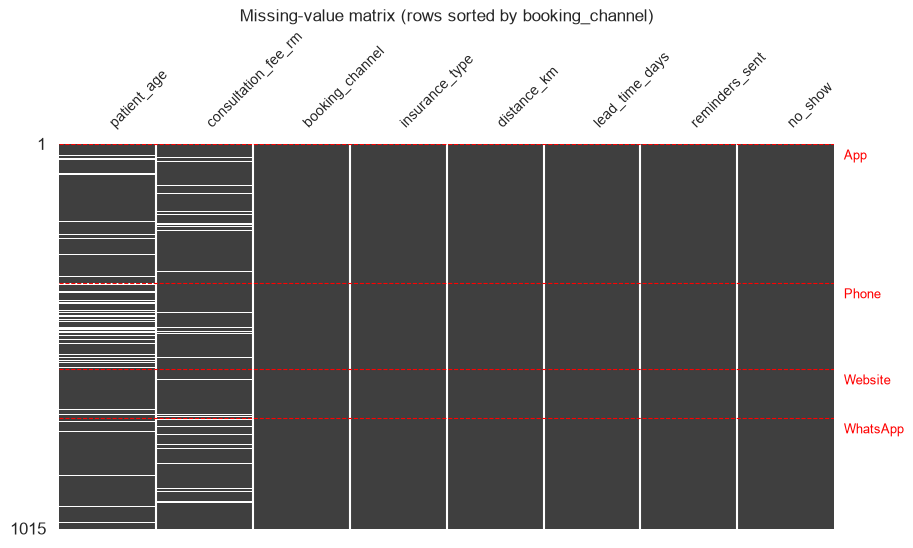

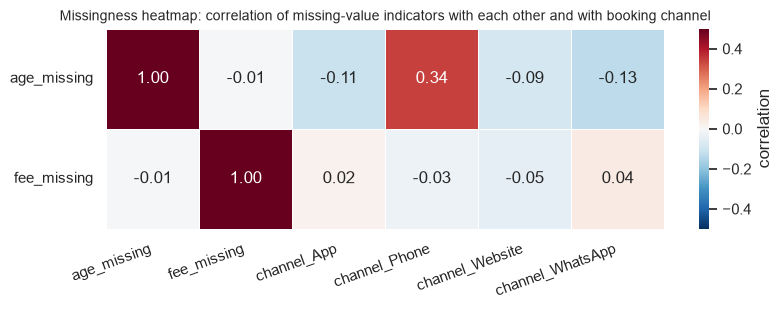

             age_missing  fee_missing  channel_App  channel_Phone  channel_Website  channel_WhatsApp
age_missing        1.000       -0.006       -0.112           0.34           -0.088            -0.130
fee_missing       -0.006        1.000        0.021          -0.03           -0.049             0.041


In [12]:
# ---------- B2.4 Missing-value matrix and heatmap ----------
# Rows sorted by booking_channel so any link between missingness and channel becomes visible
show_cols = ["patient_age", "consultation_fee_rm", "booking_channel", "insurance_type",
             "distance_km", "lead_time_days", "reminders_sent", "no_show"]
sorted_raw = raw.sort_values("booking_channel").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5))
msno.matrix(sorted_raw[show_cols], ax=ax, sparkline=False, fontsize=10)
starts = sorted_raw.groupby("booking_channel").apply(lambda g: g.index.min(), include_groups=False)
for ch, start in starts.items():
    ax.axhline(start, color="red", lw=0.8, ls="--")
    ax.text(len(show_cols) - 0.4, start + 15, ch, color="red", fontsize=9, va="top")
ax.set_title("Missing-value matrix (rows sorted by booking_channel)", fontsize=12)
plt.savefig(FIG_DIR + "b2_missing_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Heatmap: correlation between the missingness indicators and booking-channel indicators
ind = pd.DataFrame({
    "age_missing": raw["patient_age"].isna().astype(int),
    "fee_missing": raw["consultation_fee_rm"].isna().astype(int),
})
ind = ind.join(pd.get_dummies(raw["booking_channel"], prefix="channel", dtype=int))
corr = ind.corr().loc[["age_missing", "fee_missing"]]
fig, ax = plt.subplots(figsize=(9, 2.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.5, vmax=0.5, linewidths=0.5,
            cbar_kws={"label": "correlation"}, ax=ax)
ax.set_title("Missingness heatmap: correlation of missing-value indicators with each other and with booking channel",
             fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.savefig(FIG_DIR + "b2_missing_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print(corr.round(3).to_string())

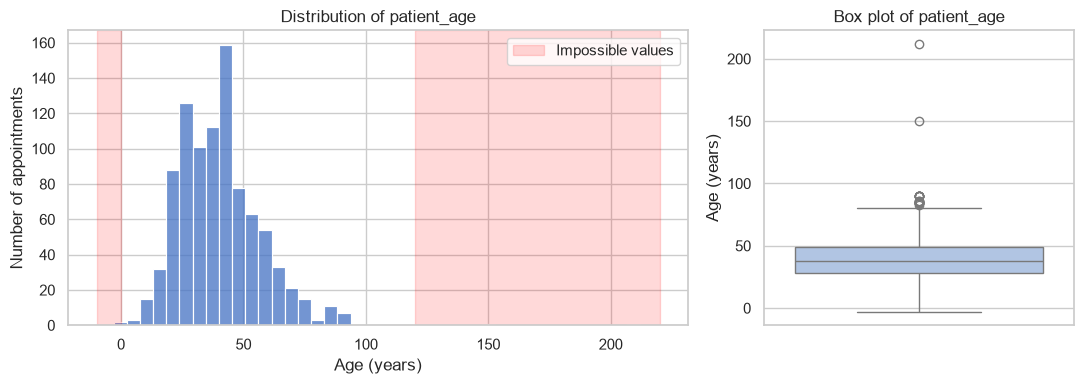

count    925.00
mean      40.25
std       17.31
min       -3.00
25%       28.00
50%       38.00
75%       49.00
max      212.00
Skewness: 1.79


In [13]:
# ---------- B2.5 Univariate visualisation: patient_age ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
sns.histplot(raw["patient_age"].dropna(), bins=40, ax=axes[0], color="#4472c4")
axes[0].axvspan(-10, 0, color="red", alpha=0.15)
axes[0].axvspan(120, 220, color="red", alpha=0.15, label="Impossible values")
axes[0].set(title="Distribution of patient_age", xlabel="Age (years)", ylabel="Number of appointments")
axes[0].legend()
sns.boxplot(y=raw["patient_age"], ax=axes[1], color="#a9c4eb")
axes[1].set(title="Box plot of patient_age", ylabel="Age (years)")
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_univariate_age.png", dpi=150, bbox_inches="tight")
plt.show()
print(raw["patient_age"].describe().round(2).to_string())
print(f"Skewness: {raw['patient_age'].skew():.2f}")

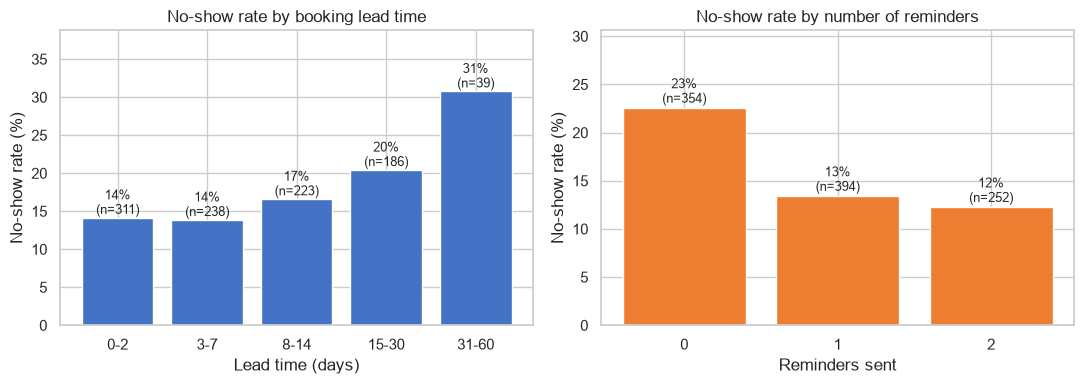

Rows with negative lead time are excluded from the lead-time chart: 3


In [14]:
# ---------- B2.6 Bivariate visualisation: no-show rate vs lead time and reminders ----------
viz = raw.drop_duplicates().copy()
viz["no_show_flag"] = (viz["no_show"] == "Yes").astype(int)
viz["lead_time_band"] = pd.cut(viz["lead_time_days"], [-1, 2, 7, 14, 30, 60],
                               labels=["0-2", "3-7", "8-14", "15-30", "31-60"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lt = viz.groupby("lead_time_band", observed=True)["no_show_flag"].agg(["mean", "size"])
axes[0].bar(lt.index.astype(str), lt["mean"] * 100, color="#4472c4")
for i, (m, s) in enumerate(zip(lt["mean"], lt["size"])):
    axes[0].text(i, m * 100 + 0.5, f"{m:.0%}\n(n={s})", ha="center", fontsize=9)
axes[0].set(title="No-show rate by booking lead time", xlabel="Lead time (days)", ylabel="No-show rate (%)")
axes[0].set_ylim(0, lt["mean"].max() * 100 + 8)

rm = viz.groupby("reminders_sent")["no_show_flag"].agg(["mean", "size"])
axes[1].bar(rm.index.astype(str), rm["mean"] * 100, color="#ed7d31")
for i, (m, s) in enumerate(zip(rm["mean"], rm["size"])):
    axes[1].text(i, m * 100 + 0.5, f"{m:.0%}\n(n={s})", ha="center", fontsize=9)
axes[1].set(title="No-show rate by number of reminders", xlabel="Reminders sent", ylabel="No-show rate (%)")
axes[1].set_ylim(0, rm["mean"].max() * 100 + 8)
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_bivariate_noshow.png", dpi=150, bbox_inches="tight")
plt.show()
print("Rows with negative lead time are excluded from the lead-time chart:", (viz["lead_time_days"] < 0).sum())

### Classifying the missingness: MCAR, MAR or MNAR?

For each incomplete column, a missingness indicator (1 = missing, 0 = observed) is tested against every other **observed** column:
- **categorical columns** → chi-square test of independence;
- **numeric columns** → Mann-Whitney U test (compares the distribution in rows where the value is missing vs observed; does not assume normality).

If missingness is unrelated to all observed columns, the data are consistent with **MCAR**. If it depends on one or more observed columns, it is **MAR**. **MNAR** (missingness depending on the unobserved value itself) cannot be tested directly from the observed data, so it is assessed by reasoning plus a within-group check. Tests are run on the de-duplicated data so that the 15 copied rows are not counted twice; out-of-range values are excluded from the numeric comparisons. Because 12 tests are run per column, a Bonferroni-adjusted threshold (0.05 / 12 ≈ 0.0042) is also reported.

In [15]:
# ---------- B2.7 Statistical tests on the missingness indicators ----------
df = raw.drop_duplicates().copy()
valid = {  # mask out impossible values for numeric comparisons
    "patient_age": df["patient_age"].between(0, 120),
    "consultation_fee_rm": df["consultation_fee_rm"] > 0,
    "lead_time_days": df["lead_time_days"] >= 0,
}
cat_test = ["booking_channel", "insurance_type", "consultation_type", "session", "doctor_type",
            "clinic_code", "day_of_week", "no_show"]
num_test = ["patient_age", "distance_km", "prior_no_shows_12m", "lead_time_days",
            "reminders_sent", "consultation_fee_rm"]

def missingness_tests(target):
    miss = df[target].isna()
    rows = []
    for c in cat_test:
        chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[c], miss))
        rows.append([c, "chi-square", round(chi2, 2), p])
    for c in num_test:
        if c == target:
            continue
        ok = valid.get(c, pd.Series(True, index=df.index)) & df[c].notna()
        if target in valid:                      # also drop rows whose target value is impossible
            ok &= valid[target] | miss
        u, p = stats.mannwhitneyu(df.loc[ok & miss, c], df.loc[ok & ~miss, c])
        rows.append([c, "Mann-Whitney U", round(u, 1), p])
    out = pd.DataFrame(rows, columns=["compared with", "test", "statistic", "p_value"])
    alpha_bonf = 0.05 / len(out)
    out["p_value"] = out["p_value"].map(lambda p: float(f"{p:.3g}"))
    out["significant (0.05)"] = np.where(out["p_value"] < 0.05, "YES", "no")
    out["significant (Bonferroni)"] = np.where(out["p_value"] < alpha_bonf, "YES", "no")
    return out.sort_values("p_value").reset_index(drop=True)

print(f"patient_age: {df['patient_age'].isna().sum()} missing")
display(missingness_tests("patient_age"))
print(f"\nconsultation_fee_rm: {df['consultation_fee_rm'].isna().sum()} missing")
display(missingness_tests("consultation_fee_rm"))

patient_age: 88 missing


,compared with,test,statistic,p_value,significant (0.05),significant (Bonferroni)
0,booking_channel,chi-square,121.74,3.250000e-26,YES,YES
1,reminders_sent,Mann-Whitney U,31346.00,3.660000e-04,YES,YES
2,clinic_code,chi-square,13.06,1.600000e-01,no,no
3,session,chi-square,3.46,1.780000e-01,no,no
4,lead_time_days,Mann-Whitney U,36521.00,1.980000e-01,no,no
5,distance_km,Mann-Whitney U,42637.00,2.970000e-01,no,no
6,day_of_week,chi-square,5.92,3.140000e-01,no,no
7,consultation_type,chi-square,1.29,5.240000e-01,no,no
8,no_show,chi-square,0.34,5.600000e-01,no,no
9,insurance_type,chi-square,0.68,7.130000e-01,no,no



consultation_fee_rm: 70 missing


,compared with,test,statistic,p_value,significant (0.05),significant (Bonferroni)
0,prior_no_shows_12m,Mann-Whitney U,28966.50,0.0803,no,no
1,lead_time_days,Mann-Whitney U,28790.00,0.1250,no,no
2,session,chi-square,3.29,0.1930,no,no
3,patient_age,Mann-Whitney U,28763.50,0.2700,no,no
4,booking_channel,chi-square,3.64,0.3030,no,no
5,clinic_code,chi-square,9.05,0.4320,no,no
6,consultation_type,chi-square,1.43,0.4900,no,no
7,reminders_sent,Mann-Whitney U,31418.00,0.6370,no,no
8,doctor_type,chi-square,0.11,0.7430,no,no
9,insurance_type,chi-square,0.58,0.7470,no,no


Missing rate (%) by booking_channel:


,n,patient_age,consultation_fee_rm
booking_channel,,,
App,360,4.2,7.5
Phone,225,27.1,5.8
Website,126,2.4,4.0
WhatsApp,289,3.1,8.7


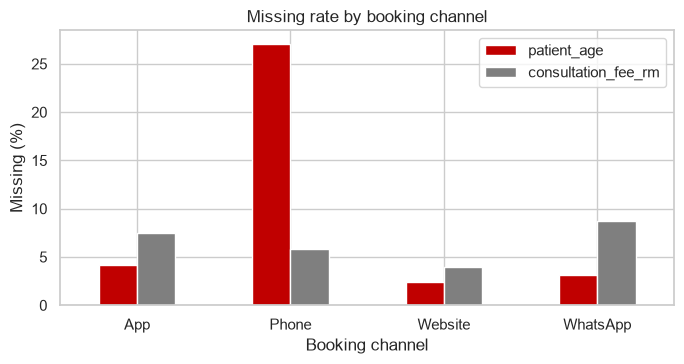

Within-channel check for patient_age (p-values; Mann-Whitney U / chi-square):


,booking_channel,n_missing,distance_km,prior_no_shows_12m,reminders_sent,insurance_type
0,App,15,0.886,0.169,0.628,0.115
1,Phone,61,0.209,0.660,0.081,0.858
2,Website,3,NaN,NaN,NaN,NaN
3,WhatsApp,9,0.023,0.322,0.279,0.930


12 within-channel tests; Bonferroni threshold = 0.05 / 12 = 0.0042
Tests below 0.05: 1 | below Bonferroni threshold: 0
(Website is skipped: fewer than 5 missing values.)


In [16]:
# ---------- B2.8 Follow-up checks ----------
# (a) Missing rate of each column by booking channel
rate_tbl = df.groupby("booking_channel")[["patient_age", "consultation_fee_rm"]] \
             .agg(lambda s: s.isna().mean() * 100).round(1)
rate_tbl.insert(0, "n", df.groupby("booking_channel").size())
print("Missing rate (%) by booking_channel:")
display(rate_tbl)

fig, ax = plt.subplots(figsize=(7, 3.8))
rate_tbl[["patient_age", "consultation_fee_rm"]].plot.bar(ax=ax, color=["#c00000", "#7f7f7f"], rot=0)
ax.set(title="Missing rate by booking channel", xlabel="Booking channel", ylabel="Missing (%)")
ax.legend(["patient_age", "consultation_fee_rm"])
plt.tight_layout()
plt.savefig(FIG_DIR + "b2_missing_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

# (b) Within each channel, is age missingness still related to other observed columns?
#     If MAR given channel, these tests should show no relationship.
print("Within-channel check for patient_age (p-values; Mann-Whitney U / chi-square):")
res = []
for ch, g in df.groupby("booking_channel"):
    m = g["patient_age"].isna()
    if m.sum() < 5:
        res.append([ch, int(m.sum())] + [np.nan] * 4); continue
    p_dist = stats.mannwhitneyu(g.loc[m, "distance_km"], g.loc[~m, "distance_km"]).pvalue
    p_prior = stats.mannwhitneyu(g.loc[m, "prior_no_shows_12m"], g.loc[~m, "prior_no_shows_12m"]).pvalue
    p_rem = stats.mannwhitneyu(g.loc[m, "reminders_sent"], g.loc[~m, "reminders_sent"]).pvalue
    p_ins = stats.chi2_contingency(pd.crosstab(g["insurance_type"], m))[1]
    res.append([ch, int(m.sum()), round(p_dist, 3), round(p_prior, 3), round(p_rem, 3), round(p_ins, 3)])
within = pd.DataFrame(res, columns=["booking_channel", "n_missing", "distance_km",
                                    "prior_no_shows_12m", "reminders_sent", "insurance_type"])
display(within)
n_tests = int(within.iloc[:, 2:].notna().sum().sum())
print(f"{n_tests} within-channel tests; Bonferroni threshold = 0.05 / {n_tests} = {0.05 / n_tests:.4f}")
print("Tests below 0.05:", int((within.iloc[:, 2:] < 0.05).sum().sum()),
      "| below Bonferroni threshold:", int((within.iloc[:, 2:] < 0.05 / n_tests).sum().sum()))
print("(Website is skipped: fewer than 5 missing values.)")

### B2 conclusion

**Missingness classification**

| Column | Missing (de-duplicated data) | Classification | Evidence from profiling |
|---|---|---|---|
| `patient_age` | 88 of 1,000 rows (8.8%) | **MAR** | Missingness depends strongly on the observed column `booking_channel`: Phone 27.1% vs App 4.2%, WhatsApp 3.1%, Website 2.4% (χ² = 121.74, p = 3.3 × 10⁻²⁶; correlation with the Phone indicator = 0.34; clearly visible in the sorted missing-value matrix). It is also related to `reminders_sent` (p = 0.00037), but this is explained by channel: phone bookings receive fewer reminders. **Within each channel**, missingness shows no relationship with distance, prior no-shows, reminders or insurance type (12 tests; 1 below 0.05, none below the Bonferroni threshold), so the dependence is on the channel. |
| `consultation_fee_rm` | 70 of 1,000 rows (7.0%) | **MCAR** | None of the 12 tests is significant, even at 0.05 (smallest p = 0.080). The missing rate is similar in every booking channel (4.0–8.7%), and the nullity correlation with `patient_age` is −0.01. Missingness behaves like a random sample of rows. |

**Why not MNAR?** MNAR means missingness depends on the missing value itself (for example, older patients refusing to give their age, or the most expensive consultations failing to be recorded). This cannot be proven or ruled out from observed data alone, but the evidence points against it:
- *Age:* within the Phone channel, patients with a missing age do not differ from those with a recorded age in insurance type, prior no-shows or reminders, all of which are correlated with age in this dataset. If missingness depended on age itself, these age-related attributes would differ.
- *Fee:* the fee level is driven almost entirely by `consultation_type` (health screenings cost far more). Missingness is unrelated to consultation type (p = 0.49), so expensive consultations are not more likely to be missing.

**Other problems found by profiling (to be fixed in B3)**
- 15 exact duplicate rows.
- Out-of-range values: 4 impossible ages (−3, −1, 150, 212), 3 negative fees, 3 negative lead times.
- Inconsistent formats: 196 rows with DD/MM/YYYY dates (the rest YYYY-MM-DD); 14 different spellings of `clinic_state`; 8 different gender labels.

## B3. Clean and standardise

## B4. Impute and evaluate

# Part C — Decision Tree Using ID3

## C4. Verify with code (scikit-learn)

## C5. Apply to own data

# Part D — Association Rule Mining Using Apriori

## D3. Verify with mlxtend